In [7]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

In [8]:
df = pd.read_csv("../data/lifestyle_disease_transformed.csv")

features = df[['Age', 'Gender', 'BMI', 'Smoking', 'Alcohol',
       'ExerciseHours', 'SleepHours', 'DietScore', 'BloodPressure',
       'BloodSugar', 'Cholesterol']].values
target = df['DiseaseRisk'].values.reshape(-1,1)

ss = StandardScaler()

features = ss.fit_transform(features)
x_train = features[:300000]
y_train = target[:300000]
x_test = features[300000:]
y_test = target[300000:]

In [9]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(x_train,y_train)

C:\Users\JATIN\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,priors,None
,var_smoothing,1e-09


In [10]:
y_pred = model.predict(x_test)

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,auc,roc_auc_score,roc_curve
def statistical_outcomes(x,y):
    mat = confusion_matrix(x,y)
    acc = accuracy_score(x,y)
    pre = precision_score(x,y)
    rec = recall_score(x,y)
    f1s = f1_score(x,y)
    _roc = roc_auc_score(x,y)
    print("Confusion matrix: \n",mat)
    print("Accuracy Score: \n",acc)
    print("Precision Score: \n",pre)
    print("Recall Score: \n",rec)
    print("F1 Score: \n",f1s)
    print("ROC_AUC Score: \n",_roc)
    p,q,r = roc_curve(y_test,y_pred)
    plt.plot(p,q)
    plt.xlabel("fpr")
    plt.ylabel("tpr")
    plt.title("Roc_curve")
    plt.show()


Confusion matrix: 
 [[137664  19490]
 [  2654  40192]]
Accuracy Score: 
 0.88928
Precision Score: 
 0.6734358768137797
Recall Score: 
 0.9380572282126687
F1 Score: 
 0.784019975031211
ROC_AUC Score: 
 0.9070193747614879


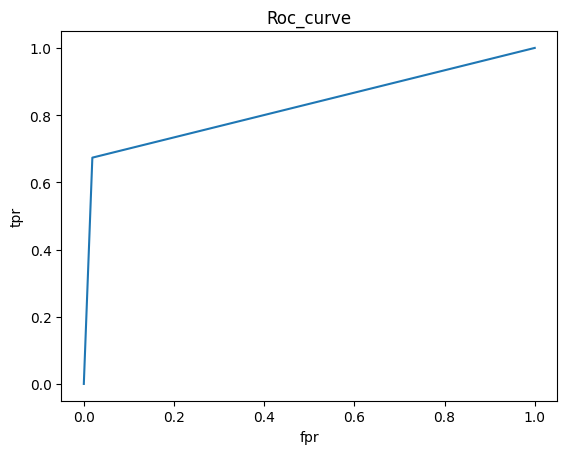

In [12]:
statistical_outcomes(y_pred,y_test)